#  Customer Retention and Performance Intelligence for a Nigerian Commercial Bank
** end-to-end analysis notebook** · Dataset: *Credit Card Customers* (BankChurners), Goyal (n.d.), Kaggle

This notebook runs the whole analytical workflow top to bottom: business understanding, data preparation, exploratory analysis and KPIs, a retention-risk score, and the evidence behind the recommendations. The reusable logic lives in `src/` (`clean.py`, `kpis.py`, `risk.py`); this notebook calls those modules and shows every intermediate result. The interactive dashboard (Task 4) is built by `src/dashboard.py`.


In [6]:
import sys, warnings, platform
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy
from IPython.display import display, Markdown, Image
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split

from src import clean as C, kpis as K, risk as R

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

EXIST, ATTR, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
                     "font.size": 10})
print(f"python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | scipy {scipy.__version__}")

python 3.14.5 | pandas 3.0.3 | scikit-learn 1.9.1 | scipy 1.18.1


##  Data cleaning and transformation

### Profiling the raw data

In [7]:
raw = C.load_raw()
print("Shape:", raw.shape)
profile = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "unique_values": raw.nunique()})
display(profile)

Shape: (10127, 23)


,dtype,missing,unique_values
CLIENTNUM,int64,0,10127
Attrition_Flag,str,0,2
Customer_Age,int64,0,45
Gender,str,0,2
Dependent_count,int64,0,6
Education_Level,str,0,7
Marital_Status,str,0,4
Income_Category,str,0,6
Card_Category,str,0,4
Months_on_book,int64,0,44


In [8]:
print("Duplicate rows:", raw.duplicated().sum(), "| duplicate customer IDs:", raw["CLIENTNUM"].duplicated().sum())
print("\nLeakage-risk columns shipped with the file:")
print([c for c in raw.columns if c.startswith("Naive")])
display(raw.filter(like="Naive").describe().loc[["min", "max"]].T.rename(index=lambda s: s[:60] + "..."))

Duplicate rows: 0 | duplicate customer IDs: 0

Leakage-risk columns shipped with the file:
['Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']


,min,max
Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts...,0.000,1.000
Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts...,0.000,1.000


The two `Naive_Bayes_Classifier...` columns have values hugging 0 or 1: they are the *output* of a classifier already trained on the attrition label. Using them as inputs would leak the answer into any model, so they are dropped.

In [9]:
# Inconsistent / placeholder labels
for c in ["Education_Level", "Marital_Status", "Income_Category", "Card_Category", "Gender"]:
    vc = raw[c].value_counts()
    print(f"{c:16s}", vc.to_dict())
print("\nLabel whitespace problems:", [c for c in raw.select_dtypes(include=['object','string']) if (raw[c] != raw[c].str.strip()).any()] or "none")

Education_Level  {'Graduate': 3128, 'High School': 2013, 'Unknown': 1519, 'Uneducated': 1487, 'College': 1013, 'Post-Graduate': 516, 'Doctorate': 451}
Marital_Status   {'Married': 4687, 'Single': 3943, 'Unknown': 749, 'Divorced': 748}
Income_Category  {'Less than $40K': 3561, '$40K - $60K': 1790, '$80K - $120K': 1535, '$60K - $80K': 1402, 'Unknown': 1112, '$120K +': 727}
Card_Category    {'Blue': 9436, 'Silver': 555, 'Gold': 116, 'Platinum': 20}
Gender           {'F': 5358, 'M': 4769}

Label whitespace problems: none


In [10]:
# Outliers  on numeric columns
num = raw.select_dtypes("number").drop(columns=["CLIENTNUM"]).drop(columns=[c for c in raw if c.startswith("Naive")])
q1, q3 = num.quantile(.25), num.quantile(.75); iqr = q3 - q1
outliers = pd.DataFrame({"min": num.min(), "max": num.max(),
                         "iqr_outliers": ((num < q1 - 1.5*iqr) | (num > q3 + 1.5*iqr)).sum()})
outliers["pct_of_rows"] = outliers["iqr_outliers"] / len(raw) * 100
display(outliers)

,min,max,iqr_outliers,pct_of_rows
Customer_Age,26.000,73.000,2,0.020
Dependent_count,0.000,5.000,0,0.000
Months_on_book,13.000,56.000,386,3.812
Total_Relationship_Count,1.000,6.000,0,0.000
Months_Inactive_12_mon,0.000,6.000,331,3.268
Contacts_Count_12_mon,0.000,6.000,629,6.211
Credit_Limit,"1,438.300","34,516.000",984,9.717
Total_Revolving_Bal,0.000,"2,517.000",0,0.000
Avg_Open_To_Buy,3.000,"34,516.000",963,9.509
Total_Amt_Chng_Q4_Q1,0.000,3.397,396,3.910


In [11]:
# Logical consistency checks between related columns
checks = {
  "Open-to-buy = credit limit - revolving balance (mismatches)": int((abs(raw.Avg_Open_To_Buy - (raw.Credit_Limit - raw.Total_Revolving_Bal)) > 1).sum()),
  "Utilisation = revolving balance / credit limit (mismatches)": int((abs(raw.Avg_Utilization_Ratio - raw.Total_Revolving_Bal / raw.Credit_Limit) > 0.01).sum()),
  "Months on book longer than adult life (age-18)": int((raw.Months_on_book > (raw.Customer_Age - 18) * 12).sum()),
  "Zero transactions but positive amount": int(((raw.Total_Trans_Ct == 0) & (raw.Total_Trans_Amt > 0)).sum()),
}
display(pd.Series(checks, name="count"))

Open-to-buy = credit limit - revolving balance (mismatches)    0
Utilisation = revolving balance / credit limit (mismatches)    0
Months on book longer than adult life (age-18)                 0
Zero transactions but positive amount                          0
Name: count, dtype: int64

### Is "Unknown" safe to impute?
Education (15.0%), marital status (7.4%) and income (11.0%) contain the placeholder `Unknown`. Before deciding how to treat it, check whether those customers behave differently from everyone else.

In [12]:
raw["_churn"] = (raw.Attrition_Flag == "Attrited Customer").astype(int)
overall = raw["_churn"].mean() * 100
rows = []
for c in ["Education_Level", "Marital_Status", "Income_Category"]:
    u = raw[raw[c] == "Unknown"]
    rows.append({"column": c, "unknown_rows": len(u), "unknown_pct": len(u)/len(raw)*100,
                 "attrition_unknown_pct": u["_churn"].mean()*100, "attrition_overall_pct": overall})
display(pd.DataFrame(rows).round(1))
raw = raw.drop(columns="_churn")

,column,unknown_rows,unknown_pct,attrition_unknown_pct,attrition_overall_pct
0,Education_Level,1519,15.000,16.900,16.100
1,Marital_Status,749,7.400,17.200,16.100
2,Income_Category,1112,11.000,16.800,16.100



### Derived analytical fields

In [13]:
clean = C.clean(raw)
derived = ["age_band", "income_segment", "tenure_band", "utilisation_band",
           "transaction_frequency_band", "spend_trend", "customer_value_class", "products_held_band"]
display(clean[["clientnum", "churned"] + derived].head(8))

,clientnum,churned,age_band,income_segment,tenure_band,utilisation_band,transaction_frequency_band,spend_trend,customer_value_class,products_held_band
0,768805383,0,45-54,Lower-middle,37-48 months,Low (0-30%),Low (<=50),Stable/growing (>1.0),Low value,5-6 products
1,818770008,0,45-54,Low income,37-48 months,Low (0-30%),Low (<=50),Stable/growing (>1.0),Low value,5-6 products
2,713982108,0,45-54,Upper-middle/High,25-36 months,None (0%),Low (<=50),Stable/growing (>1.0),Low value,3-4 products
3,769911858,0,35-44,Low income,25-36 months,High (60%+),Low (<=50),Stable/growing (>1.0),Low value,3-4 products
4,709106358,0,35-44,Lower-middle,13-24 months,None (0%),Low (<=50),Stable/growing (>1.0),Low value,5-6 products
5,713061558,0,35-44,Lower-middle,25-36 months,Medium (30-60%),Low (<=50),Mild decline (0.6-1.0),Low value,3-4 products
6,810347208,0,45-54,Upper-middle/High,37-48 months,Low (0-30%),Low (<=50),Mild decline (0.6-1.0),Low value,5-6 products
7,818906208,0,Under 35,Lower-middle,25-36 months,Low (0-30%),Low (<=50),Mild decline (0.6-1.0),Low value,1-2 products


In [14]:
# Validate each derived field: no gaps, and attrition by band
assert clean[derived].isna().sum().sum() == 0, "derived field has gaps"
for c in derived:
    t = clean.groupby(c, observed=True)["churned"].agg(customers="size", attrition_pct=lambda s: s.mean()*100)
    print(f"\n{c}"); display(t.round(1))


age_band


,customers,attrition_pct
age_band,,
Under 35,735,13.700
35-44,3440,15.900
45-54,4342,16.500
55-64,1499,16.700
65+,111,9.900



income_segment


,customers,attrition_pct
income_segment,,
Low income,3561,17.200
Lower-middle,3192,14.400
Unknown,1112,16.800
Upper-middle/High,2262,16.300



tenure_band


,customers,attrition_pct
tenure_band,,
13-24 months,847,14.900
25-36 months,5418,16.100
37-48 months,3207,16.200
49+ months,655,16.900


... (6 outputs left out)


customer_value_class


,customers,attrition_pct
customer_value_class,,
Low value,3378,31.600
Mid value,3373,7.400
High value,3376,9.100



products_held_band


,customers,attrition_pct
products_held_band,,
1-2 products,2153,26.900
3-4 products,4217,14.800
5-6 products,3757,11.300


###  Before-and-after data-quality evidence and export

In [15]:
before, after = C.quality_checks(raw), C.quality_checks(clean)
qa = pd.DataFrame({"before_cleaning": before, "after_cleaning": after})
display(qa)

,before_cleaning,after_cleaning
rows,10127,10127
columns,23,35
missing_values_total,0,0
duplicate_rows,0,0
duplicate_customer_ids,0,0
leakage_columns_present,2,0
unknown_education_level,1519,1519
unknown_marital_status,749,749
unknown_income_category,1112,1112
open_to_buy_mismatches,0,0


In [16]:
C.CLEAN.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(C.CLEAN, index=False)
print("Cleaned dataset saved:", C.CLEAN.relative_to(ROOT), clean.shape)

Cleaned dataset saved: data\processed\bank_churners_clean.csv (10127, 35)


## Task 3: Exploratory analysis and KPI development

In [17]:
scored = R.add_risk_columns(clean)           # adds rule-based risk score/band and out-of-fold churn probability
scored.to_csv(ROOT / "data" / "processed" / "bank_churners_scored.csv", index=False)

kpi = pd.Series(K.compute_kpis(scored), name="value")
display(kpi.to_frame().style.format("{:,.2f}"))

,value
Attrition rate (%),16.07
Active customer ratio (%),83.93
Average credit limit ($),"8,631.95"
Average utilisation ratio (%),27.49
"Total transaction amount, 12m ($)","44,600,182.00"
"Average transaction count, 12m",64.86
Average products held,3.81
High-risk customers (count),"1,720.00"
High-risk share of customers (%),16.98
Transaction value at risk (%),8.13


In [18]:
num_cols = ["customer_age", "months_on_book", "total_relationship_count", "months_inactive_12_mon", "contacts_count_12_mon",
            "credit_limit", "total_revolving_bal", "total_trans_amt", "total_trans_ct", "total_ct_chng_q4_q1", "utilisation_ratio"]
display(scored[num_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
customer_age,"10,127.000",46.326,8.017,26.000,41.000,46.000,52.000,73.000
months_on_book,"10,127.000",35.928,7.986,13.000,31.000,36.000,40.000,56.000
total_relationship_count,"10,127.000",3.813,1.554,1.000,3.000,4.000,5.000,6.000
months_inactive_12_mon,"10,127.000",2.341,1.011,0.000,2.000,2.000,3.000,6.000
contacts_count_12_mon,"10,127.000",2.455,1.106,0.000,2.000,2.000,3.000,6.000
credit_limit,"10,127.000","8,631.954","9,088.777","1,438.300","2,555.000","4,549.000","11,067.500","34,516.000"
total_revolving_bal,"10,127.000","1,162.814",814.987,0.000,359.000,"1,276.000","1,784.000","2,517.000"
total_trans_amt,"10,127.000","4,404.086","3,397.129",510.000,"2,155.500","3,899.000","4,741.000","18,484.000"
total_trans_ct,"10,127.000",64.859,23.473,10.000,45.000,67.000,81.000,139.000
total_ct_chng_q4_q1,"10,127.000",0.712,0.238,0.000,0.582,0.702,0.818,3.714


###  KPI values by customer segment

In [19]:
for col in ["card_category", "income_segment", "age_band", "customer_value_class"]:
    t = scored.groupby(col, observed=True).agg(customers=("churned", "size"), attrition_pct=("churned", lambda s: s.mean()*100),
                                              avg_credit_limit=("credit_limit", "mean"), avg_util=("utilisation_ratio", "mean"),
                                              avg_txn_amt=("total_trans_amt", "mean"), avg_products=("total_relationship_count", "mean")).round(2)
    print(f"\nKPIs by {col}"); display(t)


KPIs by card_category


,customers,attrition_pct,avg_credit_limit,avg_util,avg_txn_amt,avg_products
card_category,,,,,,
Blue,9436,16.100,"7,363.780",0.290,"4,225.410",3.850
Silver,555,14.770,"25,277.840",0.060,"6,590.480",3.420
Gold,116,18.100,"28,416.370",0.060,"7,685.610",3.010
Platinum,20,25.000,"30,283.450",0.040,"8,999.750",2.300



KPIs by income_segment


,customers,attrition_pct,avg_credit_limit,avg_util,avg_txn_amt,avg_products
income_segment,,,,,,
Low income,3561,17.190,"3,754.400",0.380,"4,363.420",3.820
Lower-middle,3192,14.410,"7,788.610",0.270,"4,425.430",3.810
Unknown,1112,16.820,"9,516.580",0.220,"4,282.210",3.810
Upper-middle/High,2262,16.270,"17,065.730",0.150,"4,497.910",3.800



KPIs by age_band


,customers,attrition_pct,avg_credit_limit,avg_util,avg_txn_amt,avg_products
age_band,,,,,,
Under 35,735,13.740,"7,242.800",0.300,"4,707.080",3.880
35-44,3440,15.930,"8,777.000",0.270,"4,420.860",3.840
45-54,4342,16.490,"9,135.450",0.270,"4,533.790",3.750
55-64,1499,16.740,"7,744.570",0.300,"3,972.250",3.880
65+,111,9.910,"5,623.790",0.330,"2,635.980",4.170



KPIs by customer_value_class


,customers,attrition_pct,avg_credit_limit,avg_util,avg_txn_amt,avg_products
customer_value_class,,,,,,
Low value,3378,31.650,"8,500.670",0.260,"1,776.980",4.100
Mid value,3373,7.440,"8,117.520",0.280,"3,748.260",4.210
High value,3376,9.090,"9,277.290",0.280,"7,688.000",3.130


### Attrited versus existing customers (ten variables, Mann-Whitney U test)
A rank-based test is used because most variables are skewed or bounded.

In [20]:
cmp_ = K.compare_groups(scored)
display(cmp_[["variable", "existing_mean", "attrited_mean", "existing_median", "attrited_median", "pct_difference", "p_value", "significant_5pct"]])

,variable,existing_mean,attrited_mean,existing_median,attrited_median,pct_difference,p_value,significant_5pct
0,Transactions (12m),68.673,44.934,71.000,43.000,-34.568,0.000,True
1,Transaction amount ($),"4,654.656","3,095.026","4,100.000","2,329.000",-33.507,0.000,True
2,Revolving balance ($),"1,256.604",672.823,"1,364.000",0.000,-46.457,0.000,True
3,Utilisation ratio,0.296,0.163,0.211,0.000,-45.186,0.000,True
4,Txn-count change Q4/Q1,0.742,0.554,0.721,0.531,-25.329,0.000,True
5,Products held,3.915,3.280,4.000,3.000,-16.220,0.000,True
6,Months inactive,2.274,2.693,2.000,3.000,18.451,0.000,True
7,Contacts with bank (12m),2.356,2.972,2.000,3.000,26.142,0.000,True
8,Credit limit ($),"8,726.878","8,136.039","4,643.500","4,178.000",-6.770,0.000,True
9,Age,46.262,46.660,46.000,47.000,0.859,0.078,False


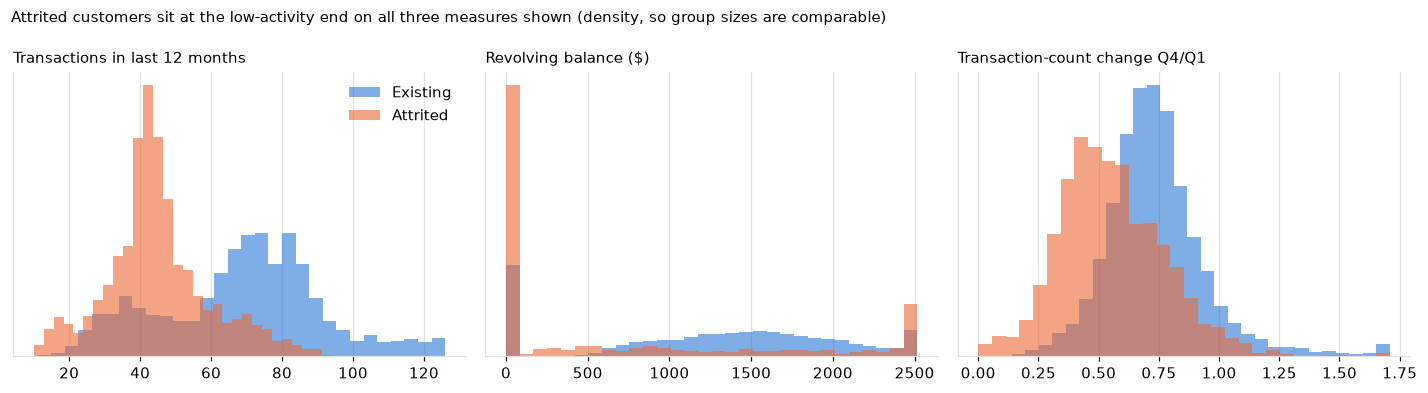

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, (col, title, bins) in zip(ax, [("total_trans_ct", "Transactions in last 12 months", 30),
                                      ("total_revolving_bal", "Revolving balance ($)", 30),
                                      ("total_ct_chng_q4_q1", "Transaction-count change Q4/Q1", 30)]):
    for churned, color, lab in [(0, EXIST, "Existing"), (1, ATTR, "Attrited")]:
        a.hist(scored.loc[scored.churned == churned, col].clip(upper=scored[col].quantile(.995)), bins=bins, alpha=.6, color=color, label=lab, density=True)
    a.set_title(title, fontsize=10, loc="left"); a.set_yticks([])
ax[0].legend(frameon=False)
plt.suptitle("Attrited customers sit at the low-activity end on all three measures shown (density, so group sizes are comparable)", fontsize=10, x=0.01, ha="left")
plt.tight_layout(); plt.show()

### Patterns that explain attrition

In [22]:
def rate(mask): return scored.loc[mask, "churned"].mean() * 100
tot_att = scored.churned.sum()

p1 = scored[(scored.transaction_frequency_band == "Low (<=50)") & (scored.spend_trend == "Sharp decline (<0.6)")]
print(f"PATTERN 1 - Low activity AND sharp spending decline: {len(p1):,} customers churn at {p1.churned.mean()*100:.1f}% "
      f"and hold {p1.churned.sum()/tot_att*100:.0f}% of all attrition. "
      f"(Highly active, no sharp decline: {rate((scored.transaction_frequency_band=='High (81+)') & (scored.spend_trend!='Sharp decline (<0.6)')):.1f}%)")

z = scored.utilisation_band == "None (0%)"
print(f"PATTERN 2 - Never revolving (0% utilisation): {z.sum():,} customers churn at {rate(z):.1f}% vs {rate(~z):.1f}% for everyone else.")

shallow = scored.total_relationship_count <= 2
print(f"PATTERN 3 - Shallow relationship (1-2 products): {shallow.sum():,} customers churn at {rate(shallow):.1f}% vs {rate(scored.total_relationship_count >= 5):.1f}% with 5-6 products.")

contacts = scored.groupby("contacts_count_12_mon")["churned"].agg(customers="size", attrition_pct=lambda s: s.mean()*100).round(1)
print("\nPATTERN 4 - Contacts with the bank in the last 12 months (customers who call more leave more):")
display(contacts.T)

print(f"\nCONTRAST - demographics: attrition by age band ranges {scored.groupby('age_band', observed=True).churned.mean().min()*100:.1f}% to "
      f"{scored.groupby('age_band', observed=True).churned.mean().max()*100:.1f}%; by income segment "
      f"{scored.groupby('income_segment', observed=True).churned.mean().min()*100:.1f}% to {scored.groupby('income_segment', observed=True).churned.mean().max()*100:.1f}%.")

PATTERN 1 - Low activity AND sharp spending decline: 1,676 customers churn at 54.8% and hold 56% of all attrition. (Highly active, no sharp decline: 1.3%)
PATTERN 2 - Never revolving (0% utilisation): 2,470 customers churn at 36.2% vs 9.6% for everyone else.
PATTERN 3 - Shallow relationship (1-2 products): 2,153 customers churn at 26.9% vs 11.3% with 5-6 products.

PATTERN 4 - Contacts with the bank in the last 12 months (customers who call more leave more):


contacts_count_12_mon,0,1,2,3,4,5,6
customers,399.000,"1,499.000","3,227.000","3,380.000","1,392.000",176.000,54.000
attrition_pct,1.800,7.200,12.500,20.100,22.600,33.500,100.000



CONTRAST - demographics: attrition by age band ranges 9.9% to 16.7%; by income segment 14.4% to 17.2%.


**Reading the patterns.** Attrition is driven by *behaviour*, not demographics: customers who transact rarely, are cutting spend, never revolve, hold few products or contact the bank repeatedly are far more likely to leave. Age and income bands, by contrast, barely move the rate. Caution: groups with very few customers (for example 6 contacts, or Platinum cards at n = 20) produce extreme rates that should not be built into rules.

### Retention-risk score
Two complementary methods are used. Neither uses the attrition label as an input; the label is used only to *evaluate* them. Thresholds were chosen by inspecting the **training split only**, and results are reported on a **held-out test split**.

**Method 1: rule-based points score (used on the dashboard).** Transparent and auditable by executives.

In [23]:
rules = pd.DataFrame(R.RULES, columns=["component", "rule (points)", "max points"])
display(rules)
print("Maximum score:", rules["max points"].sum(), "| bands: 0-3 Low, 4-6 Medium, 7+ High")

,component,rule (points),max points
0,rs_low_activity,"Transactions in last 12m <= 50 (+3), 51-60 (+2...",3
1,rs_spend_drop,"Txn-count change Q4/Q1 <= 0.5 (+3), 0.5-0.6 (+...",3
2,rs_no_revolving,Revolving balance = 0 (+2) or <= $800 (+1),2
3,rs_few_products,Holds 1-2 bank products (+1),1
4,rs_contacts,"Contacted bank 3-4 times (+1), 5+ times (+2)",2
5,rs_inactive,Inactive 3+ months in last 12 (+1),1


Maximum score: 12 | bands: 0-3 Low, 4-6 Medium, 7+ High


In [24]:
display(scored.groupby("risk_band", observed=True).agg(customers=("churned", "size"), attrited=("churned", "sum"),
        attrition_pct=("churned", lambda s: s.mean()*100), avg_txn_amt=("total_trans_amt", "mean"),
        avg_credit_limit=("credit_limit", "mean")).round(1))

,customers,attrited,attrition_pct,avg_txn_amt,avg_credit_limit
risk_band,,,,,
Low,5013,101,2.000,"5,763.000","8,577.500"
Medium,3394,425,12.500,"3,560.200","9,110.600"
High,1720,1101,64.000,"2,108.700","7,846.100"


**Method 2: logistic regression (validation).** Inputs are behavioural and product fields only. Gender, age, marital status, education, income and dependants are *deliberately excluded*: below we test what that costs.

In [25]:
ev = R.evaluate(scored)
print(f"Held-out test set: {ev['n_test']:,} customers (train {ev['n_train']:,})")
print(f"AUC  rule-based score : {ev['auc_rule_test']:.3f}")
print(f"AUC  logistic model   : {ev['auc_logit_test']:.3f}\n")
print("Attrition by risk band, TRAIN split"); display(ev["bands_train"])
print("Attrition by risk band, TEST split (unseen customers)"); display(ev["bands_test"])

Held-out test set: 3,039 customers (train 7,088)
AUC  rule-based score : 0.887
AUC  logistic model   : 0.912

Attrition by risk band, TRAIN split


,customers,attrited,attrition_rate_pct
risk_band,,,
Low,3513,63,1.800
Medium,2349,292,12.400
High,1226,784,63.900


Attrition by risk band, TEST split (unseen customers)


,customers,attrited,attrition_rate_pct
risk_band,,,
Low,1500,38,2.500
Medium,1045,133,12.700
High,494,317,64.200


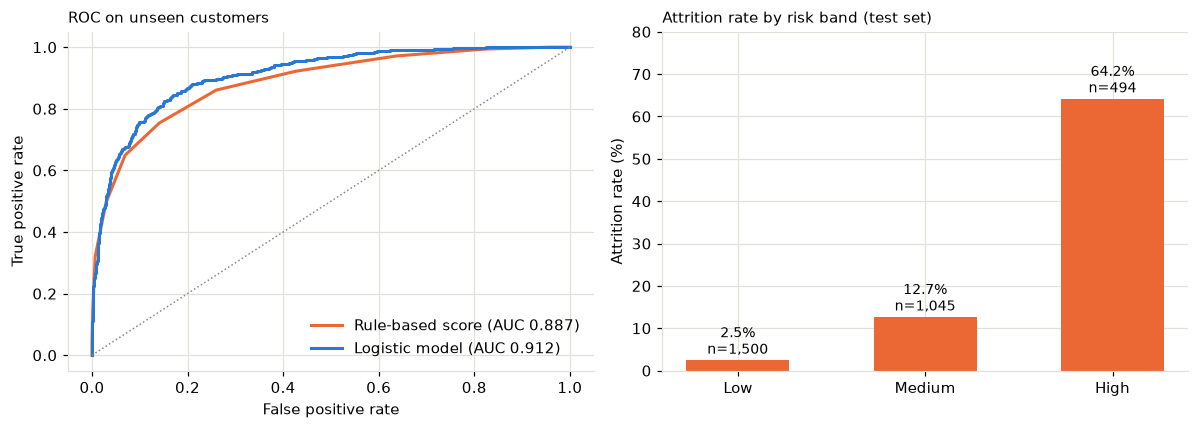

In [26]:
# ROC curves on the same held-out customers
base = scored.drop(columns=[c for c in scored if c.startswith("rs_")] + ["risk_score", "risk_band", "churn_probability"])
d = base.join(R.rule_based_score(base))
tr, te = train_test_split(d, test_size=0.3, stratify=d["churned"], random_state=R.SEED)
m = R._model().fit(R._prep(tr), tr["churned"]); p = m.predict_proba(R._prep(te))[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for y, s, lab, col in [(te.churned, te.risk_score, f"Rule-based score (AUC {roc_auc_score(te.churned, te.risk_score):.3f})", ATTR),
                       (te.churned, p, f"Logistic model (AUC {roc_auc_score(te.churned, p):.3f})", EXIST)]:
    fpr, tpr, _ = roc_curve(y, s); ax[0].plot(fpr, tpr, color=col, lw=2, label=lab)
ax[0].plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1); ax[0].legend(frameon=False, loc="lower right")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("ROC on unseen customers", loc="left", fontsize=10)
bt = ev["bands_test"]; ax[1].bar(bt.index.astype(str), bt["attrition_rate_pct"], color=ATTR, width=.55)
for i, (v, n) in enumerate(zip(bt["attrition_rate_pct"], bt["customers"])): ax[1].text(i, v + 1.5, f"{v:.1f}%\nn={n:,}", ha="center", fontsize=9)
ax[1].set_ylim(0, 80); ax[1].set_ylabel("Attrition rate (%)"); ax[1].set_title("Attrition rate by risk band (test set)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

In [27]:
# What does excluding demographics cost? Compare AUC with and without them on the same split.
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
def auc_with(num, cat):
    tf = [("n", StandardScaler(), num)] + ([("c", OneHotEncoder(handle_unknown="ignore"), cat)] if cat else [])
    mm = Pipeline([("p", ColumnTransformer(tf)), ("c", LogisticRegression(max_iter=2000))])
    X = lambda df: df[num + cat].assign(**{c: df[c].astype(str) for c in cat})
    mm.fit(X(tr), tr.churned); return roc_auc_score(te.churned, mm.predict_proba(X(te))[:, 1])
demo_num, demo_cat = ["customer_age", "dependent_count"], ["gender", "income_category", "education_level", "marital_status"]
fair = pd.Series({"Behavioural + product inputs (used)": auc_with(R.NUM, R.CAT),
                  "Plus gender, age, marital status, education, income, dependants": auc_with(R.NUM + demo_num, R.CAT + demo_cat)}, name="test AUC")
display(fair.to_frame()); print(f"Accuracy given up by excluding demographics: {fair.iloc[1]-fair.iloc[0]:.4f} AUC")

,test AUC
Behavioural + product inputs (used),0.912
"Plus gender, age, marital status, education, income, dependants",0.915


Accuracy given up by excluding demographics: 0.0027 AUC


Excluding demographics costs almost nothing, so there is no justification for scoring customers on gender, age or marital status. This is also the answer to the governance question of whether a retention score could treat customer groups unequally.

### Does the score flag customer groups at similar rates? (fairness monitoring)

In [28]:
fl = scored.assign(high=(scored.risk_band == "High").astype(int))
for col in ["gender", "age_band", "income_segment"]:
    t = fl.groupby(col, observed=True).agg(customers=("high", "size"), flagged_high_pct=("high", lambda s: s.mean()*100),
                                          actual_attrition_pct=("churned", lambda s: s.mean()*100)).round(1)
    print(f"\n{col}"); display(t)


gender


,customers,flagged_high_pct,actual_attrition_pct
gender,,,
F,5358,16.600,17.400
M,4769,17.400,14.600



age_band


,customers,flagged_high_pct,actual_attrition_pct
age_band,,,
Under 35,735,16.600,13.700
35-44,3440,15.700,15.900
45-54,4342,16.600,16.500
55-64,1499,21.300,16.700
65+,111,16.200,9.900



income_segment


,customers,flagged_high_pct,actual_attrition_pct
income_segment,,,
Low income,3561,16.400,17.200
Lower-middle,3192,16.900,14.400
Unknown,1112,17.800,16.800
Upper-middle/High,2262,17.600,16.300


Flag rates are similar across gender (16.6% female, 17.4% male) and income segments (16.4% to 17.8%). **Customers aged 55-64 are the exception:** they are flagged High-risk at 21.3%, against 15.7% to 16.6% for the other large age bands, although their actual attrition (16.7%) is in line with the others. Men are also flagged slightly above their actual attrition (17.4% versus 14.6%). The score uses no age or gender input, so these gaps come from behavioural differences between groups; whether they reflect genuine behaviour or an artefact should be reviewed before the score is used on those groups. This is exactly why the table should be re-run each time the score is refreshed.

### Logistic coefficients (direction only)

In [29]:
display(ev["logit_top_coefficients"].to_frame("standardised coefficient"))

,standardised coefficient
num__total_trans_ct,-2.537
num__total_trans_amt,1.403
num__total_revolving_bal,-0.770
num__total_relationship_count,-0.760
cat__card_category_Blue,-0.705
num__total_ct_chng_q4_q1,-0.656
cat__card_category_Gold,0.527
num__contacts_count_12_mon,0.519
num__months_inactive_12_mon,0.518
cat__card_category_Silver,-0.277




### Calibration of the model's churn probability (out-of-fold)

In [30]:
cal = scored.assign(decile=pd.qcut(scored.churn_probability, 10, labels=False, duplicates="drop") + 1)
display(cal.groupby("decile").agg(customers=("churned", "size"), mean_predicted=("churn_probability", "mean"), actual_rate=("churned", "mean")).round(3))

,customers,mean_predicted,actual_rate
decile,,,
1,1020,0.002,0.000
2,1013,0.005,0.005
3,1006,0.010,0.010
4,1018,0.018,0.020
5,1012,0.030,0.031
6,1007,0.052,0.057
7,1014,0.095,0.085
8,1011,0.188,0.186
9,1013,0.408,0.423


## Task 4: Dashboard and visualisation
The dashboard is a self-contained interactive HTML file built with Plotly (`src/dashboard.py` - `outputs/retention_dashboard.html`), exported to PDF and PNG with `src/export_dashboard.py`.

* **Page 1, Executive overview:** 8 KPI cards, attrition by transaction frequency, by risk band (score validation), by card category, by age and income.
* **Page 2, Customer retention analysis:** activity × spending-trend heatmap, transaction scatter, attrited-vs-existing indexed comparison, relationship depth and card usage, risk-band segmentation table, priority outreach list.
* **Controls:** five filters (card category, income segment, age band, gender, risk band) apply to every KPI, chart and table on both pages; each chart has a table view.
* **Chart choices:** horizontal bars on a zero baseline for rates (with sample sizes printed, so small groups are not over-read), a heatmap for the two-way grid, a scatter for the shape of two groups, and an *indexed* bar chart so measures with different units share one axis (no dual-axis chart). One colour per entity throughout (Attrited orange, Existing blue).

**Page 1: Executive overview**

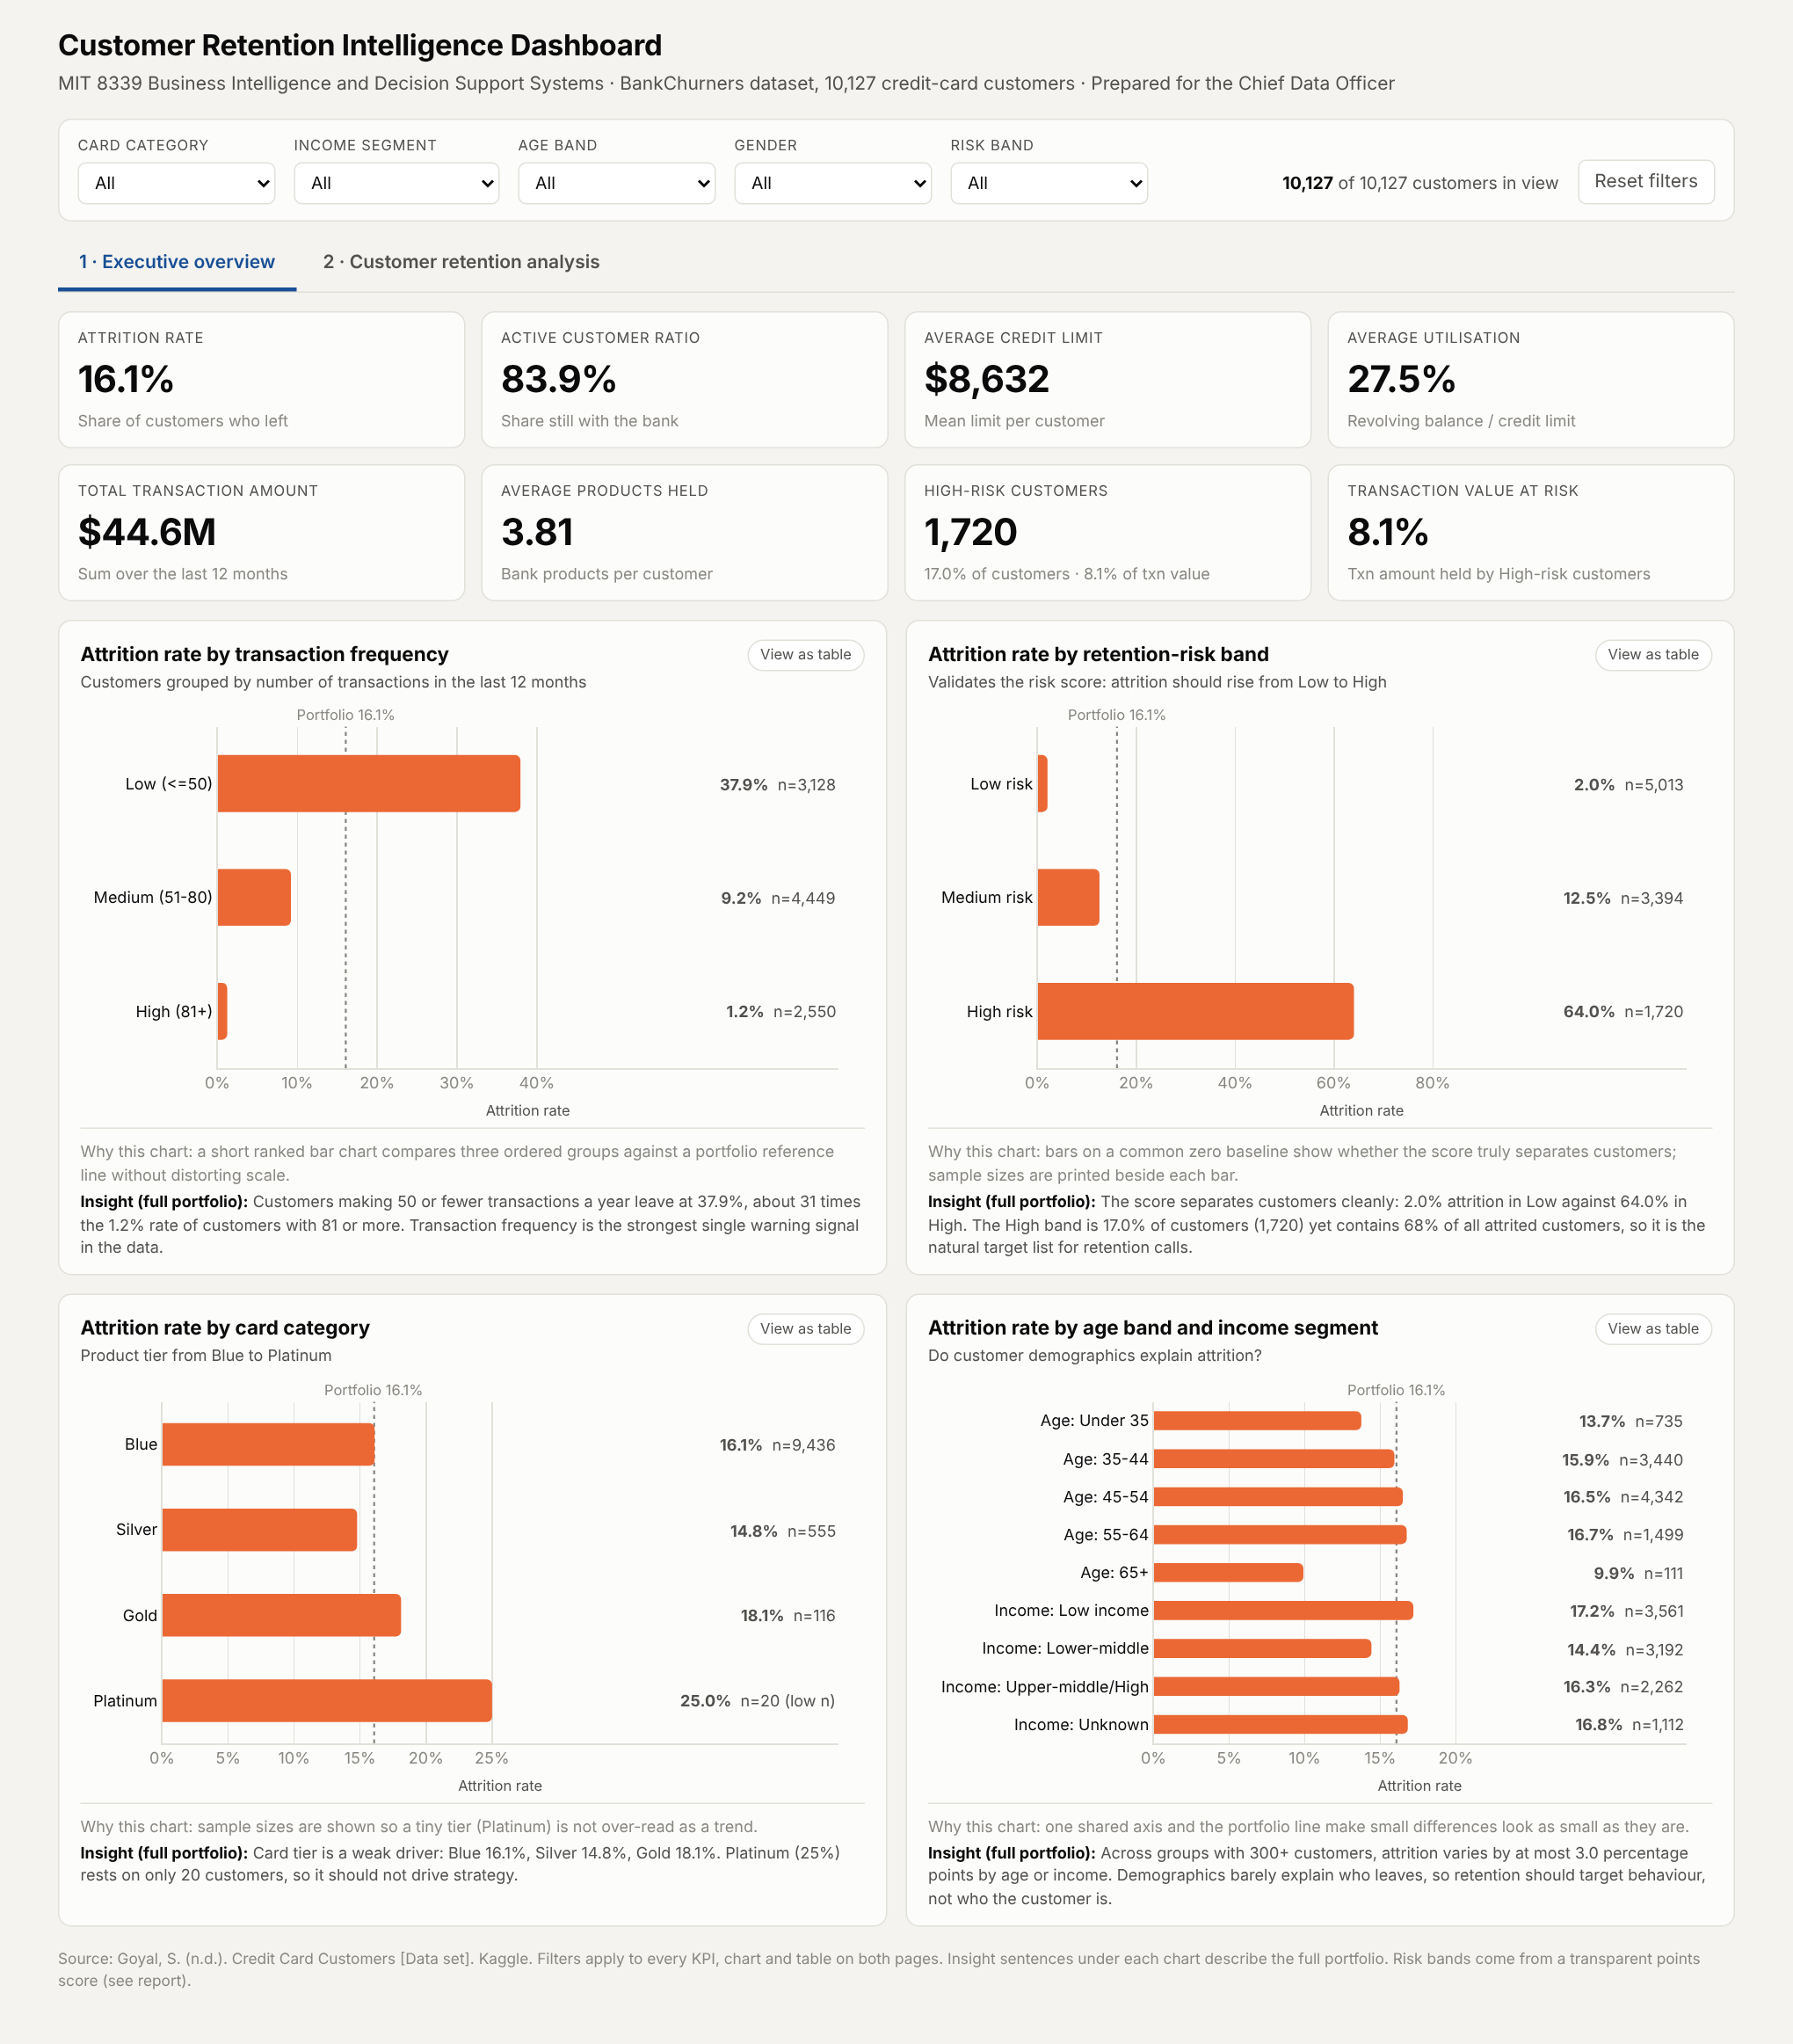

**Page 2: Customer retention analysis**

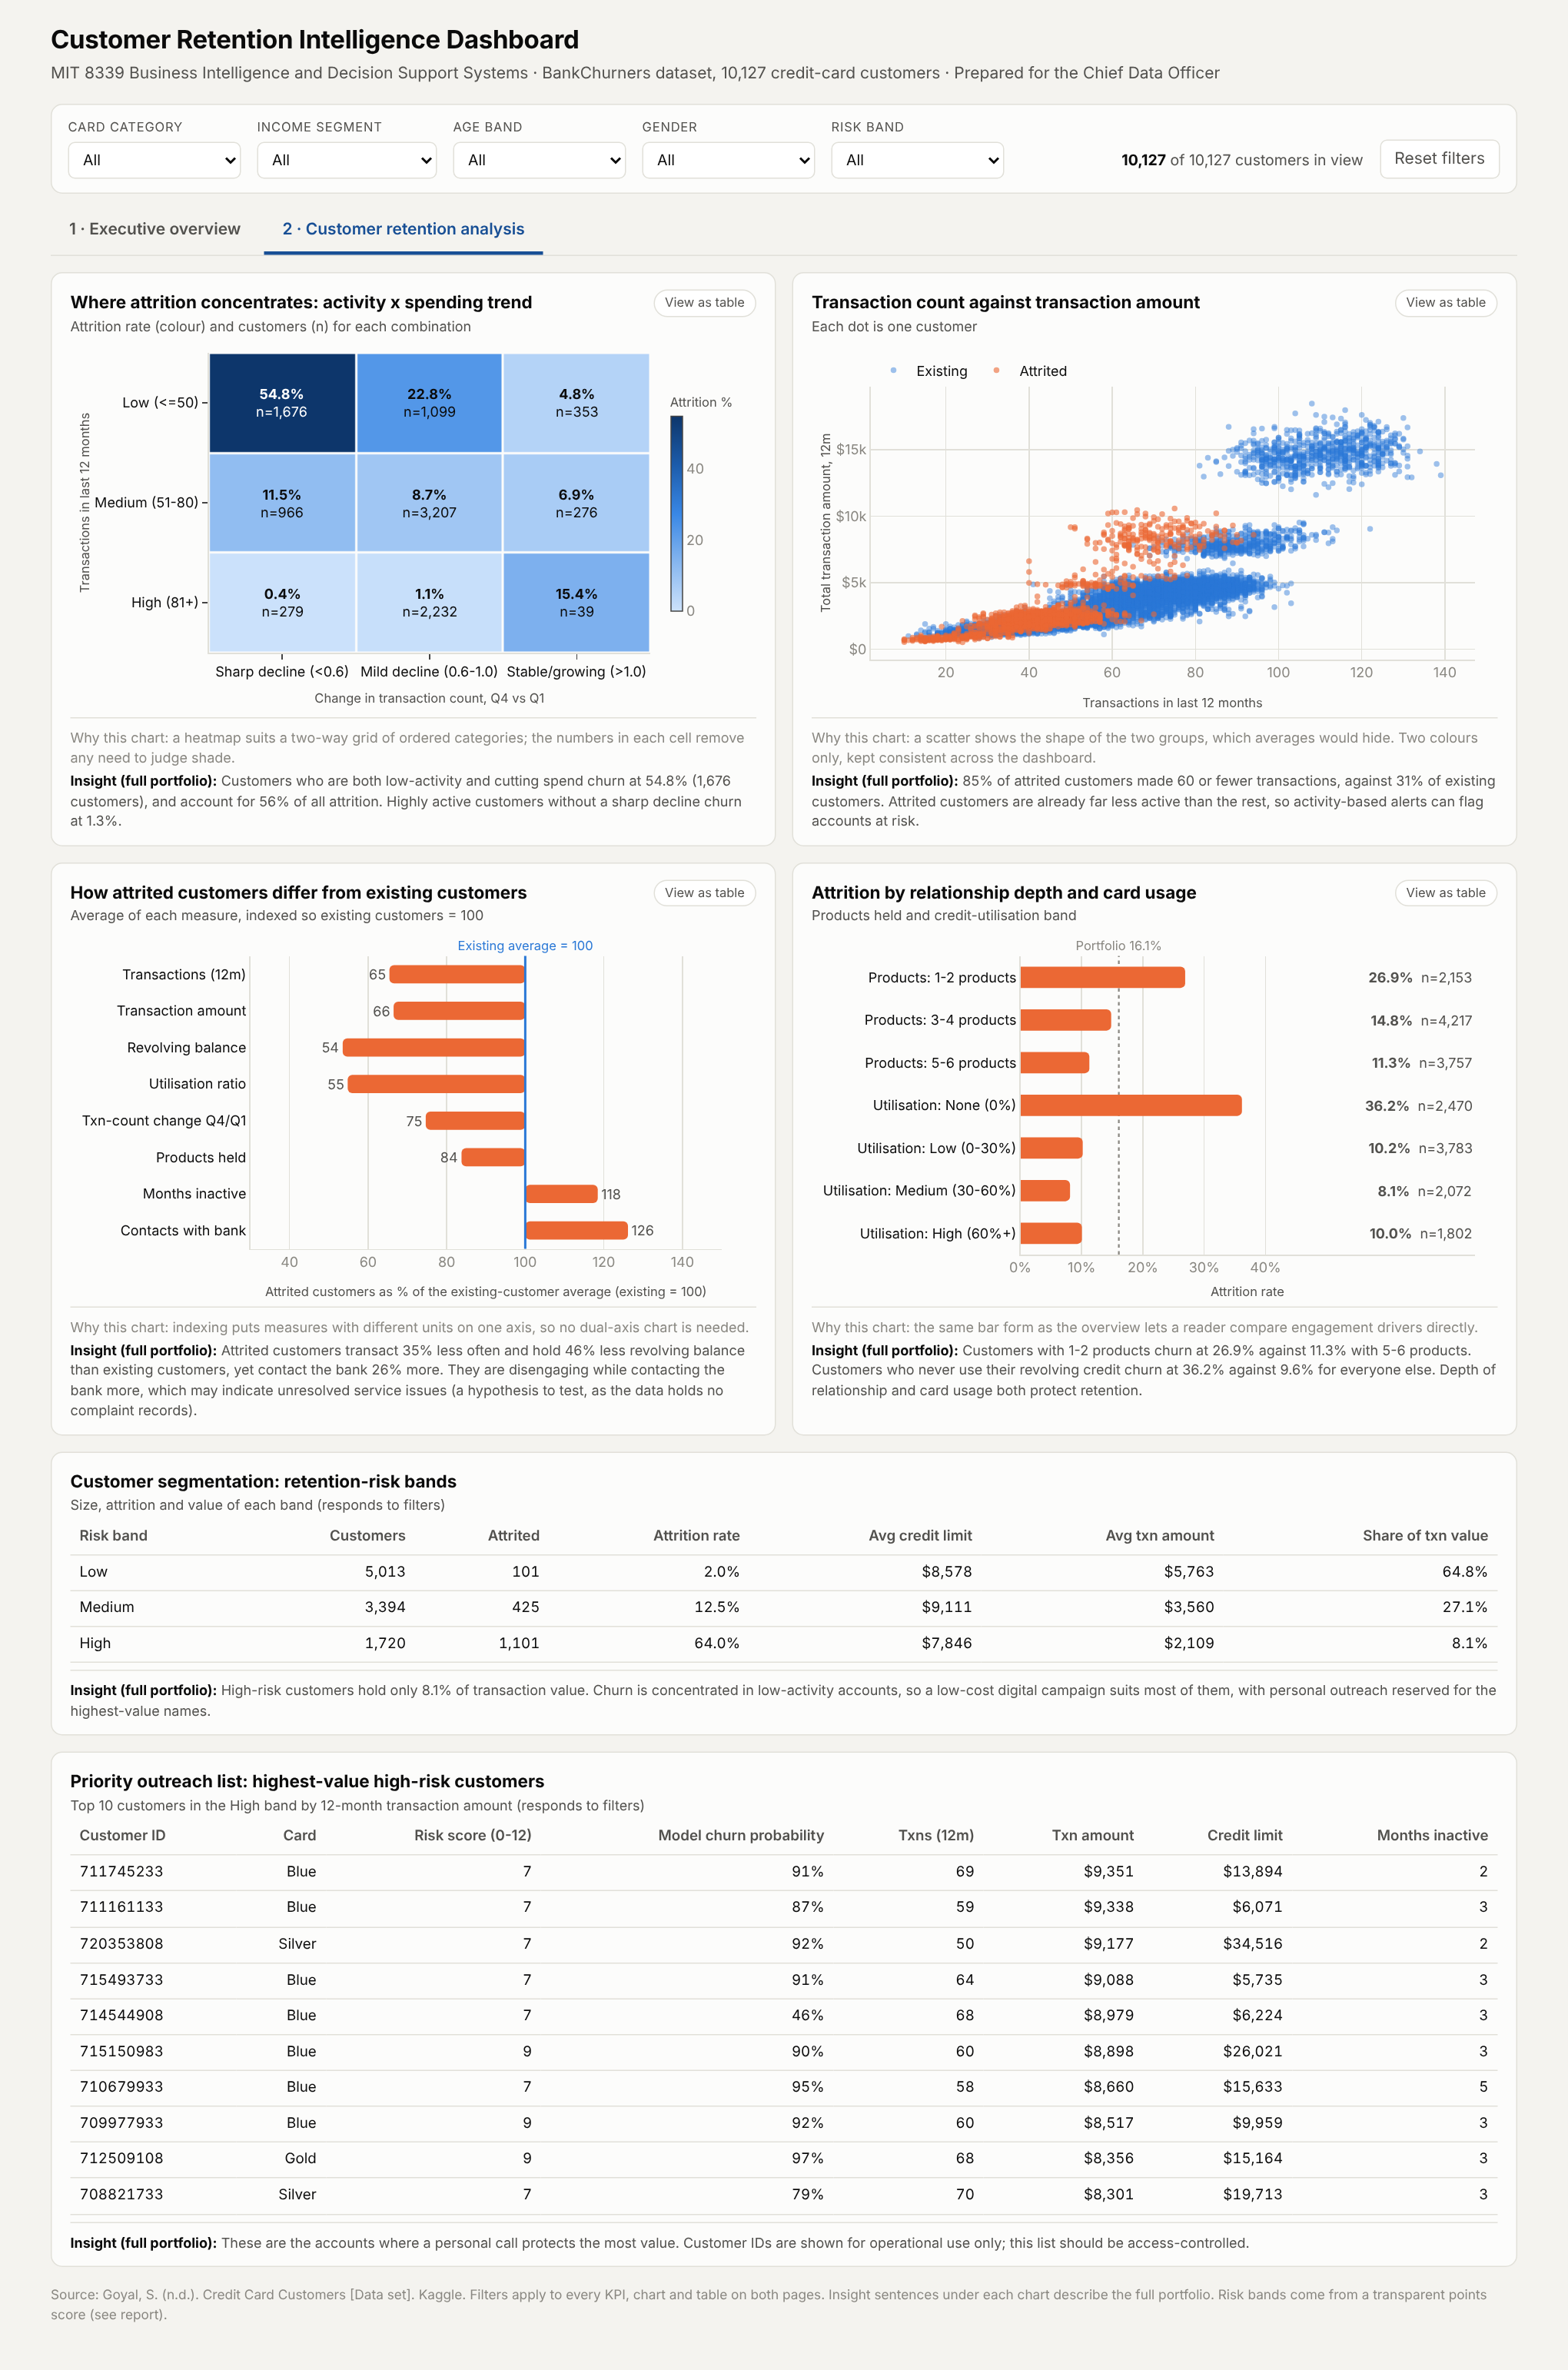

**Filter evidence: Risk band = High (all KPIs and charts recompute)**

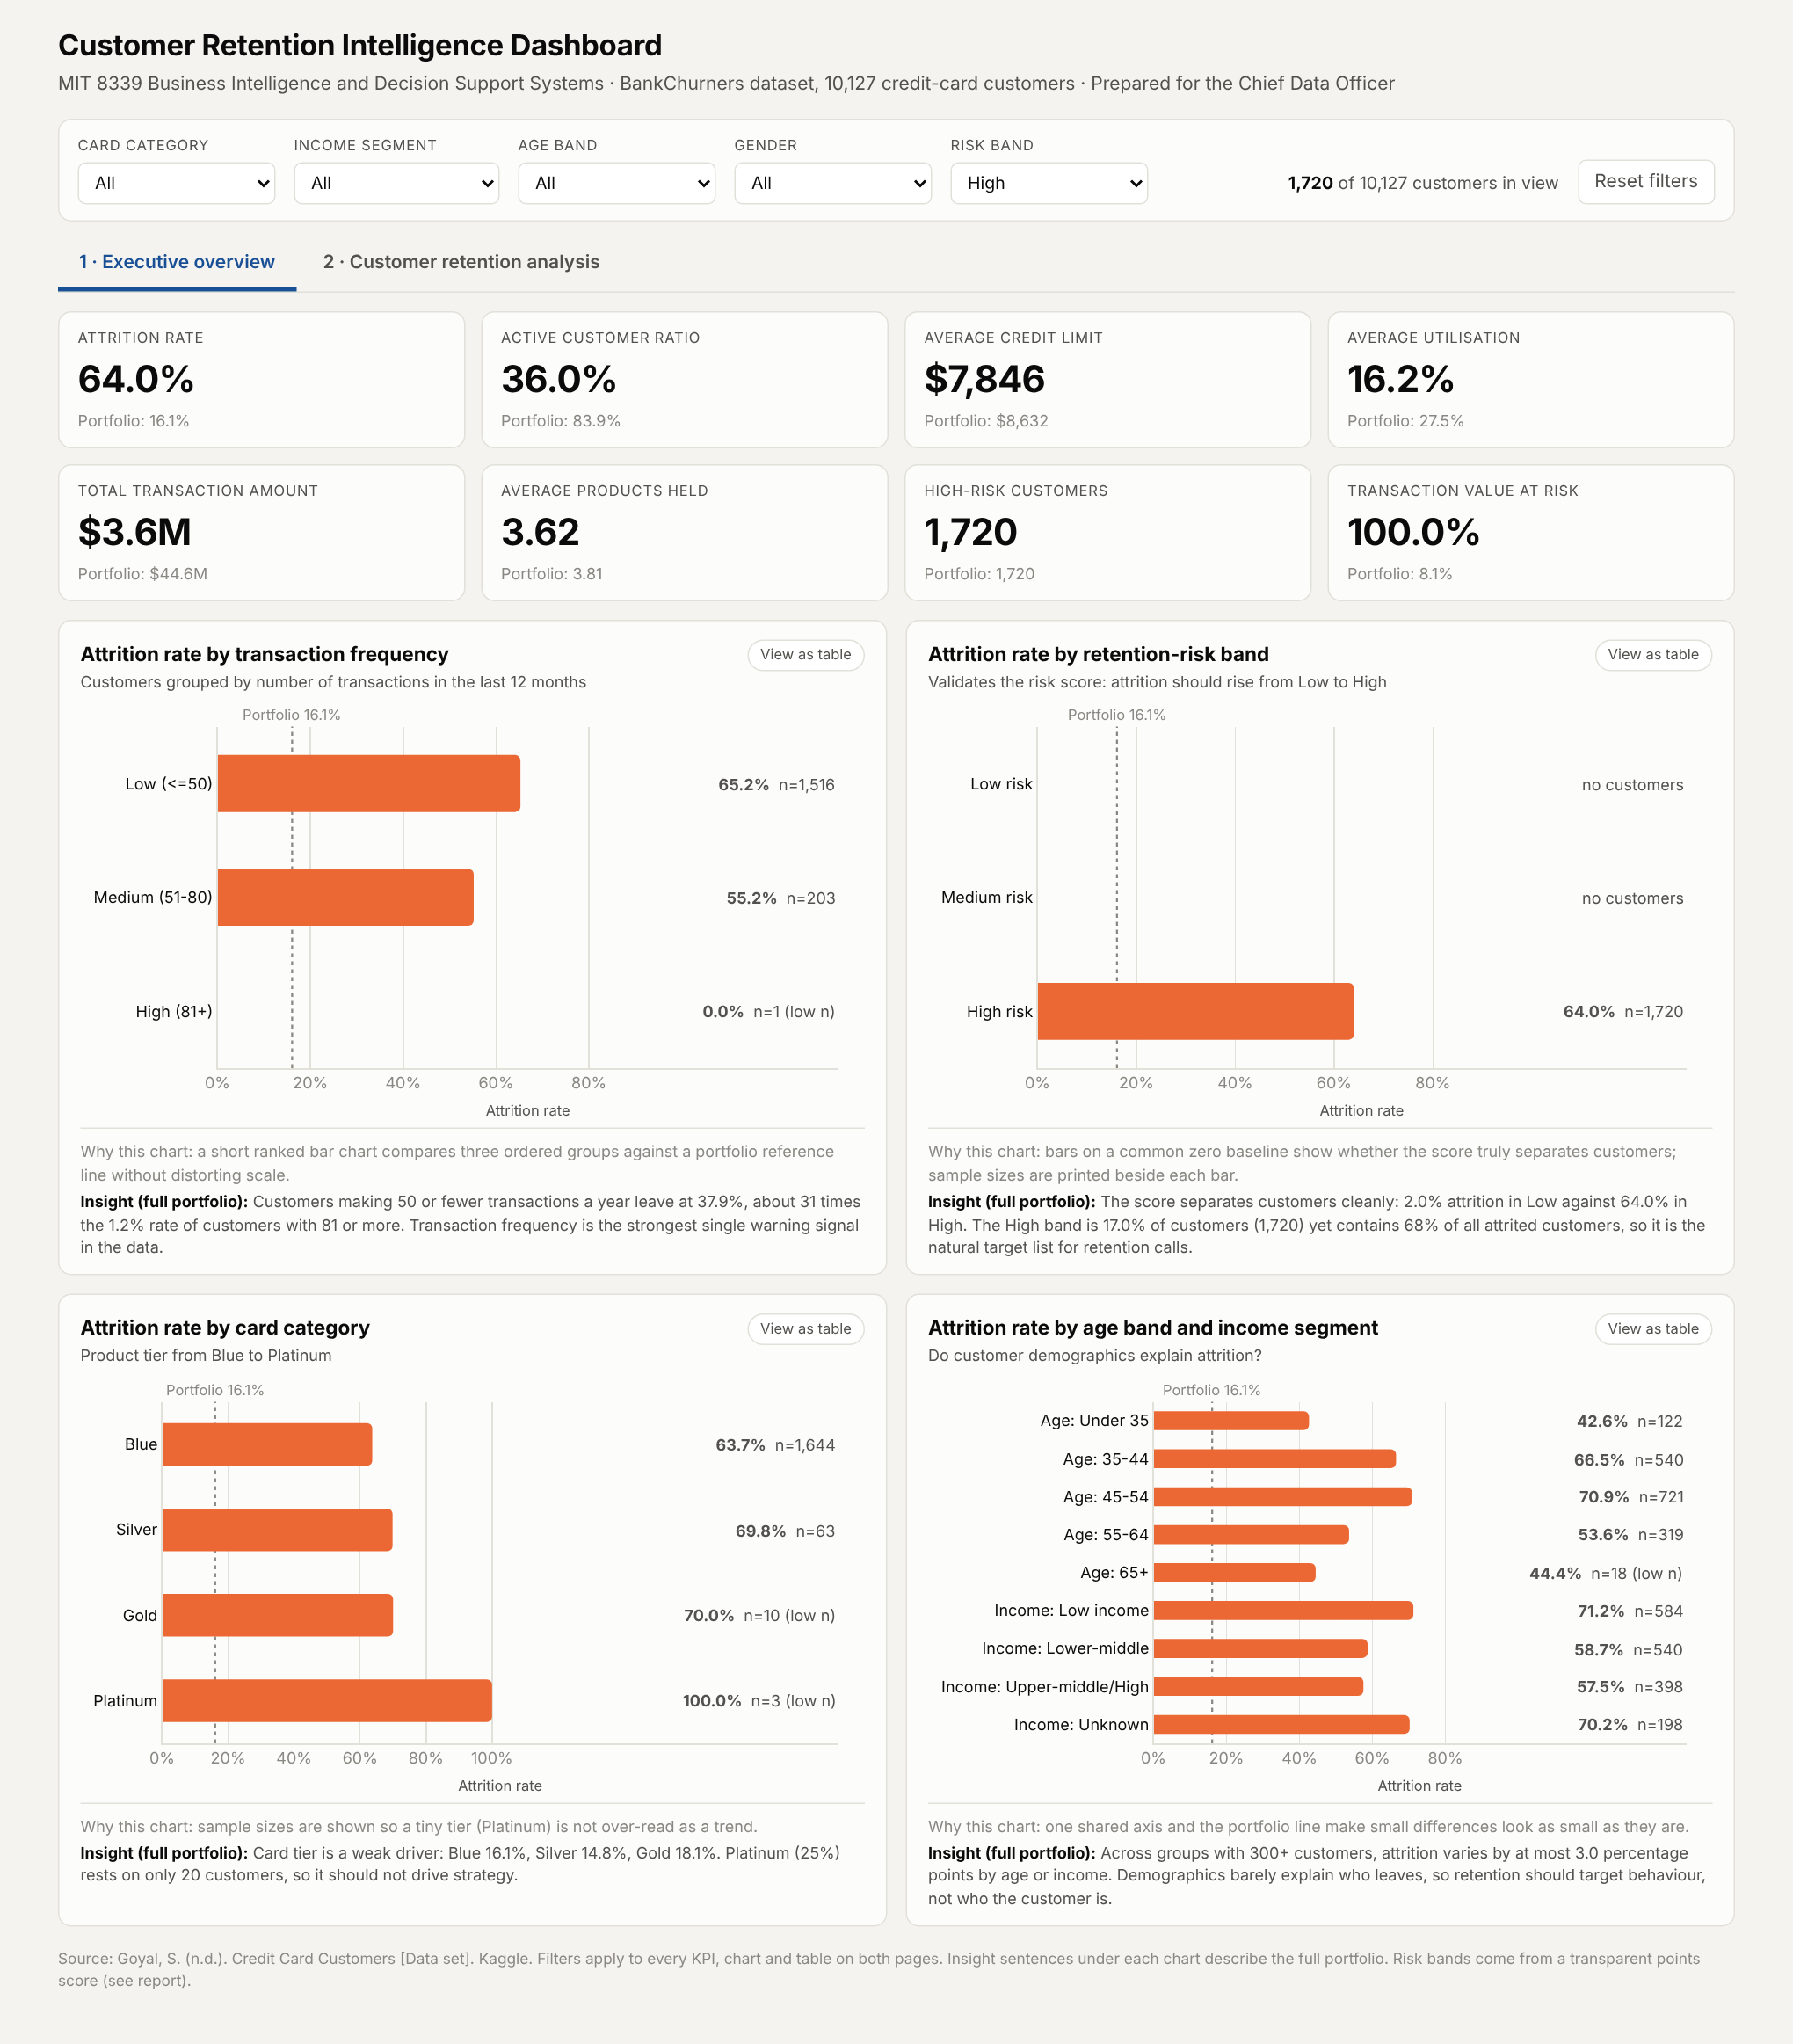

In [31]:
for f, cap in [("dashboard_page1_overview.png", "Page 1: Executive overview"),
               ("dashboard_page2_retention.png", "Page 2: Customer retention analysis"),
               ("dashboard_page1_filtered_high_risk.png", "Filter evidence: Risk band = High (all KPIs and charts recompute)")]:
    p = ROOT / "outputs" / "figures" / f
    if p.exists():
        display(Markdown(f"**{cap}**")); display(Image(filename=str(p), width=900))

In [35]:

##Acurracy checks
v = pd.read_csv(ROOT / "outputs" / "dashboard_filter_validation.csv")
display(v.pivot(index="kpi", columns="filter_combination", values="dashboard").loc[list(dict.fromkeys(v.kpi))])
print("KPI values checked:", len(v), "| matching pandas:", int((v.match == "PASS").sum()))

filter_combination,1. No filters,2. Risk band = High,"3. Card = Blue, Gender = F","4. Age 45-54, Low income, Risk = Medium"
kpi,,,,
Attrition rate,16.1%,64.0%,17.4%,14.4%
Active customer ratio,83.9%,36.0%,82.6%,85.6%
Average credit limit,"$8,632","$7,846","$4,308","$3,966"
Average utilisation,27.5%,16.2%,35.5%,32.7%
Total transaction amount,$44.6M,$3.6M,$21.4M,$1.6M
Average products held,3.81,3.62,3.83,3.93
High-risk customers,"1,720","1,720",865,0
Transaction value at risk,8.1%,100.0%,8.7%,0.0%


KPI values checked: 32 | matching pandas: 32


In [ ]:
###Additional Figures 

## Task 5: Evidence for decision-support recommendations
The numbers below are the evidence base for the report's recommendations. Scenario figures are **illustrations under stated assumptions**, not forecasts: the dataset contains no information on what retention actions cost or achieve.

In [32]:
hi = scored[scored.risk_band == "High"]
ev_rows = {
  "R1 Target High-risk band": (len(hi), hi.churned.mean()*100, hi.churned.sum()/tot_att*100),
  "R2 Low activity AND sharp spend decline": (len(p1), p1.churned.mean()*100, p1.churned.sum()/tot_att*100),
  "R3 Zero card utilisation": (int(z.sum()), rate(z), scored[z].churned.sum()/tot_att*100),
  "R4 Only 1-2 products held": (int(shallow.sum()), rate(shallow), scored[shallow].churned.sum()/tot_att*100),
  "R5 Contacted bank 4+ times in 12m": (int((scored.contacts_count_12_mon >= 4).sum()), rate(scored.contacts_count_12_mon >= 4),
                                        scored[scored.contacts_count_12_mon >= 4].churned.sum()/tot_att*100),
}
evidence = pd.DataFrame(ev_rows, index=["customers", "attrition_rate_pct", "share_of_all_attrition_pct"]).T
display(evidence.round(1))


,customers,attrition_rate_pct,share_of_all_attrition_pct
R1 Target High-risk band,"1,720.000",64.000,67.700
R2 Low activity AND sharp spend decline,"1,676.000",54.800,56.500
R3 Zero card utilisation,"2,470.000",36.200,54.900
R4 Only 1-2 products held,"2,153.000",26.900,35.600
R5 Contacted bank 4+ times in 12m,"1,622.000",26.400,26.300


In [33]:
# Illustrative scenario: customers retained if an intervention keeps a share of the High-band customers who would otherwise leave
leave = int(hi.churned.sum()); avg_amt = hi.loc[hi.churned == 1, "total_trans_amt"].mean()
sc = pd.DataFrame({"assumed_save_rate": [0.10, 0.20, 0.30]})
sc["customers_retained"] = (leave * sc.assumed_save_rate).round(0).astype(int)
sc["attrition_rate_after_pct"] = (scored.churned.sum() - sc.customers_retained) / len(scored) * 100
sc["annual_txn_value_kept_$"] = (sc.customers_retained * avg_amt).round(0)
print(f"High-band customers expected to leave: {leave:,}; average 12-month transaction amount of those leavers: ${avg_amt:,.0f}")
display(sc.round(2))

High-band customers expected to leave: 1,101; average 12-month transaction amount of those leavers: $2,266


,assumed_save_rate,customers_retained,attrition_rate_after_pct,annual_txn_value_kept_$
0,0.100,110,14.980,"249,276.000"
1,0.200,220,13.890,"498,551.000"
2,0.300,330,12.810,"747,827.000"


## Reproducibility log

In [34]:
outs = sorted(p.relative_to(ROOT).as_posix() for p in (ROOT / "outputs").rglob("*") if p.is_file())
print("Files produced by the pipeline:"); [print("  ", o) for o in outs]
print("\nRandom seed for all splits and folds:", R.SEED)

Files produced by the pipeline:
   outputs/attrited_vs_existing.csv
   outputs/data_quality_report.csv
   outputs/figures/dashboard_page1_filtered_high_risk.png
   outputs/figures/dashboard_page1_overview.png
   outputs/figures/dashboard_page2_filtered_high_risk.png
   outputs/figures/dashboard_page2_retention.png
   outputs/kpis.csv
   outputs/model_metrics.csv
   outputs/retention_dashboard.html
   outputs/retention_dashboard.pdf
   outputs/risk_bands_test.csv
   outputs/risk_bands_train.csv
   outputs/segment_age_band.csv
   outputs/segment_card_category.csv
   outputs/segment_customer_value_class.csv
   outputs/segment_income_segment.csv
   outputs/segment_products_held_band.csv
   outputs/segment_risk_band.csv
   outputs/segment_spend_trend.csv
   outputs/segment_transaction_frequency_band.csv
   outputs/segment_utilisation_band.csv

Random seed for all splits and folds: 42
